Initial Dataset Shape: (10000, 2)

First 3 rows:
   label                                             review
0   pos  Stuning even for the non-gamer: This sound tra...
1   pos  The best soundtrack ever to anything.: I'm rea...
2   pos  Amazing!: This soundtrack is my favorite music...

Missing Values: {'label': 0, 'review': 0}
Dataset Shape after removing duplicates: (10000, 2)

Class Distribution:
 label
neg    5097
pos    4903
Name: count, dtype: int64

Training Feature Matrix Shape: (8000, 5000)
Testing Feature Matrix Shape: (2000, 5000)

--- Logistic Regression Performance ---
Accuracy:  0.8490
Precision: 0.8504
Recall:    0.8400
F1-Score:  0.8451

--- Support Vector Machine (SVM) Performance ---
Accuracy:  0.8405
Precision: 0.8337
Recall:    0.8430
F1-Score:  0.8383

=== Model Comparison Table ===


,Metric,Logistic Regression,Support Vector Machine
0,Accuracy,0.849000,0.840500
1,Precision,0.850361,0.833669
2,Recall,0.839959,0.843017
3,F1-Score,0.845128,0.838317


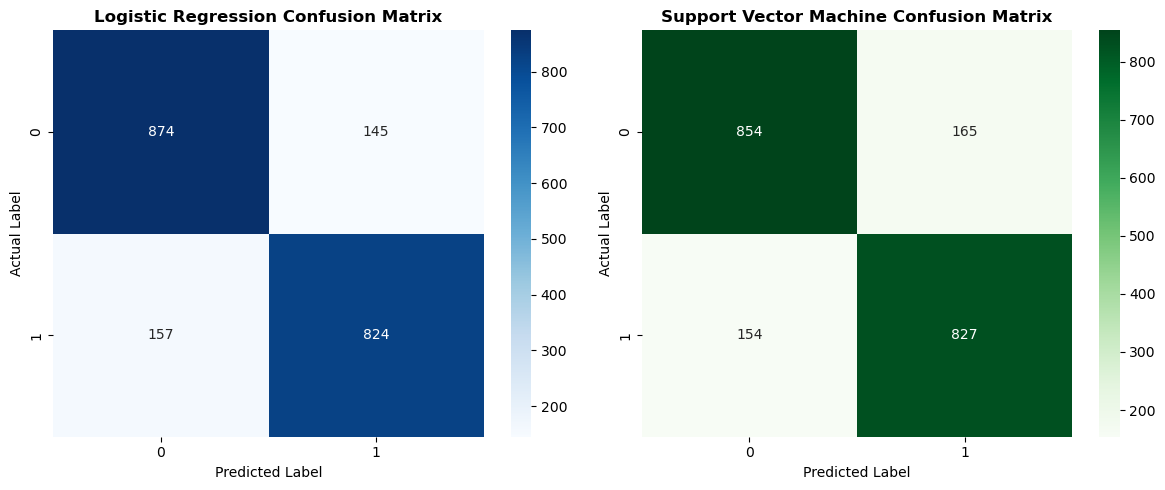

In [2]:
# Assignment 19: NLP Text Classification & Sentiment Analysis
# Case Study: Improving Customer Satisfaction through Amazon Review Analysis
# Import necessary libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Ensure reproducibility
np.random.seed(42)

# 1. Data Exploration and Preprocessing
# Load the dataset (TSV format separated by tabs)
df = pd.read_csv('amazonreviews.tsv', sep='\t')
print("Initial Dataset Shape:", df.shape)
print("\nFirst 3 rows:\n", df.head(3))

# Check for missing values and duplicates
print("\nMissing Values:", df.isnull().sum().to_dict())
df = df.drop_duplicates().reset_index(drop=True)
print("Dataset Shape after removing duplicates:", df.shape)

# Check class distribution
print("\nClass Distribution:\n", df['label'].value_counts())

# Text Cleaning Function
def clean_text(text):
    if not isinstance(text, str):
        return ""
    # Convert to lowercase
    text = text.lower()
    # Remove HTML tags if any
    text = re.sub(r'<.*?>', '', text)
    # Remove special characters and numbers (keep alphanumeric and basic punctuation)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Remove extra whitespaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply text cleaning
df['cleaned_review'] = df['review'].apply(clean_text)

# Encode labels: 'pos' -> 1, 'neg' -> 0
df['target'] = df['label'].map({'pos': 1, 'neg': 0})


# 2. Train-Test Split & Feature Extraction
X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned_review'], df['target'], test_size=0.20, random_state=42, stratify=df['target']
)

# TF-IDF Feature Extraction (unigrams and bigrams, max 5000 features, English stopwords removal)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"\nTraining Feature Matrix Shape: {X_train_tfidf.shape}")
print(f"Testing Feature Matrix Shape: {X_test_tfidf.shape}")


# 3. Model Development & Training

# Model 1: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)
y_pred_lr = lr_model.predict(X_test_tfidf)

# Model 2: Support Vector Machine (Linear SVC)
svm_model = LinearSVC(random_state=42, max_iter=1000)
svm_model.fit(X_train_tfidf, y_train)
y_pred_svm = svm_model.predict(X_test_tfidf)

# 4. Evaluation & Performance Comparison

def evaluate_model(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    print(f"\n--- {name} Performance ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    return acc, prec, rec, f1

lr_metrics = evaluate_model(y_test, y_pred_lr, "Logistic Regression")
svm_metrics = evaluate_model(y_test, y_pred_svm, "Support Vector Machine (SVM)")

# Comparison Summary DataFrame
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Logistic Regression': lr_metrics,
    'Support Vector Machine': svm_metrics
})

print("\n=== Model Comparison Table ===")
display(comparison_df)


# 5. Confusion Matrix Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Support Vector Machine Confusion Matrix', fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()